In [1]:
import ROOT
import pandas as pd
import numpy as np
import os
import sys
import ipynbname
from pathlib import Path

project_root = str(ipynbname.path().parent.parent)
sys.path.append(project_root)
project_root=Path(project_root)

from processing import SiphraAcquisition, MetadataLoader, MatchedSiphraAcquisition, match_events
from analysis import fit_peak_expbg

# Constants
BITS12 = 2**12+10
BITS9 = 2**9 # 512 typical number of bins used

# Energy emission peaks in MeV
K40_MEV = [1.460]
TL208_MEV = [2.614]
CS137_MEV = [0.661]
ANNIHIL_MEV = 0.511
NA22_MEV = [ANNIHIL_MEV, 1.2745, 1.2745+ANNIHIL_MEV]
CO60_MEV = [(1.1732+1.3325)/2, 1.1732+1.3325] # First value is the average of the two photopeaks. They have the same branching ratio

colors = [
    ROOT.kRed,
    ROOT.kBlue,
    ROOT.kGreen + 2,
    ROOT.kOrange + 7,
    ROOT.kMagenta,
    ROOT.kCyan + 2,
    ROOT.kViolet,
    ROOT.kAzure + 7,
    ROOT.kPink + 7,
    ROOT.kTeal + 3,
    ROOT.kSpring + 5,
    ROOT.kYellow + 2,
    ROOT.kOrange + 1,
    ROOT.kBlue - 7,
    ROOT.kRed - 7,
    ROOT.kGray + 2,
    ROOT.kBlack,
    ROOT.kSpring - 7
]

In [2]:
files = sorted((project_root/'data/261012').glob('A_0*.csv'))

acqs = [SiphraAcquisition(file) for file in files]


In [3]:
#histogram
hists = {}
#acq = acq_src

sources = ['Cs-137', 'Co-60', 'Na-22']

channels = ['Ch1', 'Ch2', "Ch3", "Ch4", "Ch5", "Ch6", "Ch7", "Ch8", "Ch9", "Ch10", "Ch11", "Ch12", "Ch13", "Ch14",
            "Ch15", "Ch16", "Siphra_sum", "Manual_sum"]
for i, source in enumerate(sources):
    bg = acqs[0]
    sgnl = acqs[i+1]
    for channel in channels:
        hist_sgnl = ROOT.TH1F(f"{channel}_{source}_signal", "", BITS12, 0, BITS12)
        hist_bg = ROOT.TH1F(f"{channel}_{source}_BG", "", BITS12, 0, BITS12)
        if channel == "Manual_sum":
            hist_sgnl.Fill(sgnl[channel]/16)
            hist_bg.Fill(bg[channel]/16)
        else: 
            hist_sgnl.Fill(sgnl[channel])
            hist_bg.Fill(bg[channel])

        hist_bg.Scale(sgnl.exposure/bg.exposure)

        hist_clean = hist_sgnl.Clone(f"{channel}_{source}_clean")
        hist_clean.Add(hist_bg, -1)

        for hist in [hist_sgnl, hist_bg, hist_clean]:
            # hist.SetTitle(r"^{22}Na spectra - CI gain = 1/0.75 pC")
            hist.GetXaxis().SetTitle("ADC channel number")
            hist.GetYaxis().SetTitle(r"Normalized counts")

        hists[f"{channel}_{source}_signal"] = hist_sgnl
        hists[f"{channel}_{source}_clean"] = hist_clean
        del hist_sgnl
        del hist_clean
#print(hists)

In [4]:
channels = ['Ch1', 'Ch2', 'Ch3', 'Ch4', 'Ch5', 'Ch6', 'Ch7', 'Ch8', 'Ch9', 'Ch10', 'Ch11', 'Ch12', 'Ch13', 'Ch14',
            'Ch15', 'Ch16']
            #, 'Siphra_sum', 'Manual_sum']



if ROOT.gROOT.FindObject('cv'):
    ROOT.gROOT.FindObject('cv').Close()

cv = ROOT.TCanvas('cv', 'cv', 1400, 1000)
cv.Divide(2, 2)

lgds = [ROOT.TLegend(0.48, 0.61, 0.75, 0.83) for _ in range(4)]

for i, source in enumerate(sources):
    cv.cd(i+1)
    cv.cd(i+1).SetLogy()
    lg = lgds[i]
    for j, channel in enumerate(channels):
        hist = hists[f"{channel}_{source}_signal"]
        hist.SetStats(0)
        hist.SetTitle(f"{source} - SIPHRA A")
        lg.AddEntry(hist, channel)
        hist.SetLineColor(colors[j])
        if j == 0:
            hist.Draw("hist")
        else:
            hist.Draw("sames hist")
        ROOT.gPad.Update()
        
        
    lg.Draw()
    cv.Draw()

In [5]:
channels = ["Siphra_sum", "Manual_sum"]


if ROOT.gROOT.FindObject('cv'):
    ROOT.gROOT.FindObject('cv').Close()

cv = ROOT.TCanvas('cv', 'cv', 1400, 1000)
cv.Divide(2, 2)

lgds = [ROOT.TLegend(0.48, 0.61, 0.75, 0.83) for _ in range(4)]

for i, source in enumerate(sources):
    cv.cd(i+1)
    cv.cd(i+1).SetLogy()
    lg = lgds[i]
    for j, channel in enumerate(channels):
        hist = hists[f"{channel}_{source}_clean"]
        hist.SetStats(0)
        hist.SetTitle(f"{source} - SIPHRA A")
        lg.AddEntry(hist, channel)
        hist.SetLineColor(colors[j+1])
        if j == 0:
            hist.Draw("hist")
        else:
            hist.Draw("sames hist")
        ROOT.gPad.Update()
        
        
    lg.Draw()
    cv.Draw()

#print(hists)

In [6]:
channels = ["Siphra_sum", "Manual_sum"]


if ROOT.gROOT.FindObject('cv'):
    ROOT.gROOT.FindObject('cv').Close()

cv = ROOT.TCanvas('cv', 'cv', 1400, 1000)
cv.Divide(2, 2)

lgds = [ROOT.TLegend(0.48, 0.61, 0.75, 0.83) for _ in range(4)]

for i, source in enumerate(sources):
    cv.cd(i+1)
    cv.cd(i+1).SetLogy()
    lg = lgds[i]
    for j, channel in enumerate(channels):
        hist = hists[f"{channel}_{source}_signal"]
        hist.SetStats(0)
        hist.SetTitle(f"{source} - SIPHRA A")
        lg.AddEntry(hist, channel)
        hist.SetLineColor(colors[j+1])
        if j == 0:
            hist.Draw("hist")
        else:
            hist.Draw("sames hist")
        ROOT.gPad.Update()
        
        
    lg.Draw()
    cv.Draw()

In [7]:
from analysis import *


sources = ['Cs-137', 'Na-22', 'Co-60']
channels = ["Siphra_sum", "Manual_sum"]

energies = {}
energies['Cs-137'] = CS137_MEV
energies['Na-22'] = NA22_MEV
energies['Co-60'] = CO60_MEV

ranges_ss = {}
#ranges_ss['Cs-137'] = [[350, 500]] #Baseline subtracted
ranges_ss['Cs-137'] = [[370, 470]] #No baseline subtracted SIPHRA A

#ranges_ss["Co-60"] = [[600, 800],[1220, 1380]] #Baseline subtracted
ranges_ss["Co-60"] = [[620, 780], [1210, 1370]] #No baseline subtraction

#ranges_ss['Na-22'] = [[270, 420],[650, 770],[860, 1000]] 
ranges_ss['Na-22'] = [[290, 390],[660, 770],[880, 980]] #No baseline subtraction
#[[110, 200], [370, 500], [530, 640]]


ranges_ms = {}
#ranges_ms['Cs-137'] = [[230, 360]] #Baseline subtracted
ranges_ms['Cs-137'] = [[370, 470]] #No baseline subtracted SIPHRA A

#ranges_ms['Co-60'] = [[460, 650],[1010, 1150]] #Baseline subtracted
ranges_ms['Co-60'] = [[580, 750],[1150, 1280]] #No baseline subtracted SIPHRA A  

#ranges_ms['Na-22'] = [[150, 290],[510, 610],[700, 830]] #Baseline subtracted
ranges_ms['Na-22'] = [[280, 410],[640, 740],[830, 950]] #No baseline subtraction SIPHRA A



ranges = {}
ranges['Siphra_sum'] = ranges_ss
ranges['Manual_sum'] = ranges_ms

energy_vs_diff = []
resolutions = [ [],[] ]


for source in sources:
    means = []
    for i, channel in enumerate(channels):
        rng = ranges[channel][source]
        hist = hists[f"{channel}_{source}_clean"]
        means.append([])
        #resolutions.append([])

        
        
        for j, r in enumerate(rng):
            gauss = ROOT.TF1(f"gauss_{channel}_{source}_clean", "gaus", r[0], r[1])
            hist.Fit(gauss, "R+S")
            mean = gauss.GetParameter(1)
            means[i].append(mean)
            resolution = energy_resolution(hist, [r])
            print(f"Energy resolution {source} {energies[source][j]:.4g} MeV {channel}: {resolution[0]*100:.3g} %" )
            resolutions[i].append((energies[source][j], resolution[0]*100))

    for m in range(len(means[0])):
        diff = means[0][m]/means[1][m]
        diff2 = (means[0][m]-means[1][m])/means[0][m]
        #print(diff2)
        print(f"{source} (energy: {energies[source][m]:.4g} MeV), diff: {(diff2)*100:.3g} %") 
        energy_vs_diff.append((energies[source][m], diff2*100))

#print(energy_vs_diff)
print(resolutions)


Energy resolution Cs-137 0.661 MeV Siphra_sum: 25.9 %
Energy resolution Cs-137 0.661 MeV Manual_sum: 24.9 %
Cs-137 (energy: 0.661 MeV), diff: 0.625 %
Energy resolution Na-22 0.511 MeV Siphra_sum: 33.6 %
Energy resolution Na-22 1.274 MeV Siphra_sum: 16.1 %
Energy resolution Na-22 1.785 MeV Siphra_sum: 13.7 %
Energy resolution Na-22 0.511 MeV Manual_sum: 32.5 %
Energy resolution Na-22 1.274 MeV Manual_sum: 15.1 %
Energy resolution Na-22 1.785 MeV Manual_sum: 13.1 %
Na-22 (energy: 0.511 MeV), diff: 0.488 %
Na-22 (energy: 1.274 MeV), diff: 2.89 %
Na-22 (energy: 1.785 MeV), diff: 4.73 %
Energy resolution Co-60 1.253 MeV Siphra_sum: 21.9 %
Energy resolution Co-60 2.506 MeV Siphra_sum: 11.8 %
Energy resolution Co-60 1.253 MeV Manual_sum: 19.8 %
Energy resolution Co-60 2.506 MeV Manual_sum: 11.3 %
Co-60 (energy: 1.253 MeV), diff: 2.37 %
Co-60 (energy: 2.506 MeV), diff: 6.09 %
[[(0.661, 25.910343341855828), (0.511, 33.6203920360315), (1.2745, 16.100689279142), (1.7854999999999999, 13.7209660216

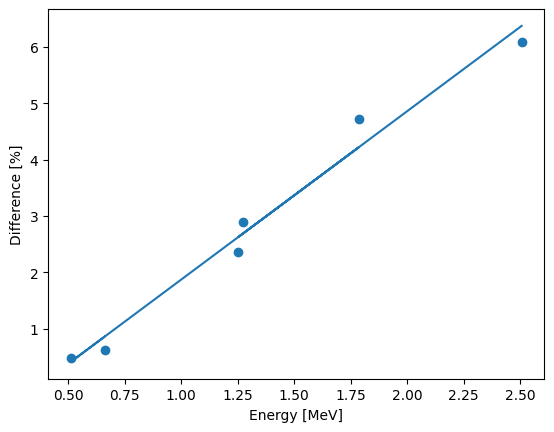

In [8]:
import matplotlib.pyplot as plt

#data = [(1, 2), (2, 4), (3, 3), (4, 7), (5, 6)]

x, y = zip(*energy_vs_diff)

m, b = np.polyfit(x, y, 1)

plt.scatter(x, y, marker="o")

plt.plot(x, np.array(x) * m + b, label=f"fit: y = {m:.2f}x + {b:.2f}")

plt.xlabel("Energy [MeV]")
plt.ylabel("Difference [%]")
plt.show()



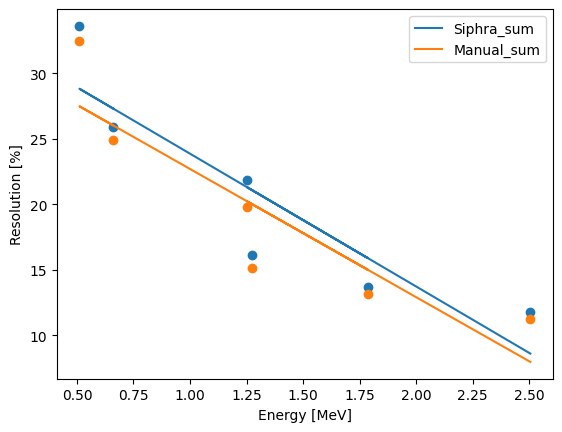

In [9]:
import matplotlib.pyplot as plt

for i in range(2):

    data = resolutions[i]
    channel = channels[i]
    x, y = zip(*data)
    m, b = np.polyfit(x, y, 1)
    
    plt.scatter(x, y, marker="o")
    
    plt.plot(x, np.array(x) * m + b, label=f"{channel}")
    
    plt.xlabel("Energy [MeV]")
    plt.ylabel("Resolution [%]")
plt.legend()    
plt.show()

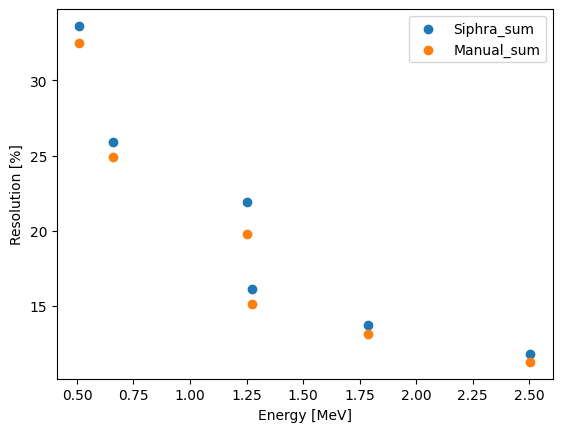

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

def exponential(x, A, B):
    return A * np.exp(B * x)

for i in range(2):

    channel = channels[i]

    data = resolutions[i]
    x, y = zip(*data)

    # Exclude the 3rd point (index 2)
    #x = np.delete(x, 2)
    #y = np.delete(y, 2)

    # Fit exponential
    popt, pcov = curve_fit(exponential, x, y)
    A, B = popt

    # Scatter data
    plt.scatter(x, y, marker="o", label=f"{channel}")

    # Smooth fitted curve
    #x_fit = np.linspace(min(x), max(x), 200)
    #y_fit = exponential(x_fit, A, B)

    #plt.plot(x_fit, y_fit, label=f"{channel}")

    plt.xlabel("Energy [MeV]")
    plt.ylabel("Resolution [%]")

plt.legend()
plt.show()

SIPHRAAcquisition(File: 'A_03_18ChTest_Co60')


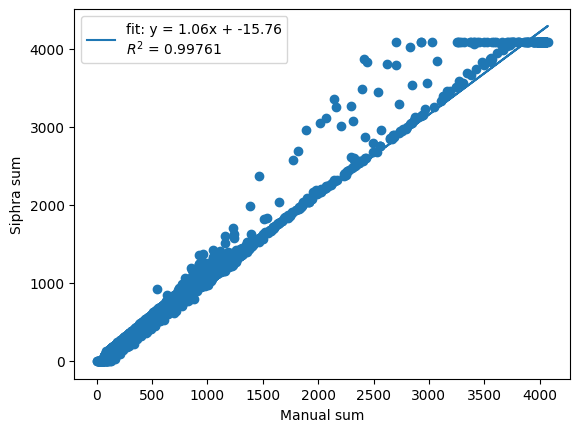

Slope: 1.0582623630882722
Intercept: -15.759302532552173
R²: 0.9976101192795416


In [11]:
data = acqs[2]
print(data)

ms = data['Manual_sum'] /16
ss = data['Siphra_sum']

plt.scatter(ms, ss, marker='o')

# Linear fit
m, b = np.polyfit(ms, ss, 1)

# Predicted values from the fit
ss_fit = m * np.array(ms) + b

# Calculate R^2
ss_res = np.sum((ss - ss_fit)**2)
ss_tot = np.sum((ss - np.mean(ss))**2)
r_squared = 1 - ss_res / ss_tot

# Plot
plt.plot(
    ms,
    ss_fit,
    label=f"fit: y = {m:.2f}x + {b:.2f}\n$R^2$ = {r_squared:.5f}"
)

plt.ylabel("Siphra sum")
plt.xlabel("Manual sum")

plt.legend()
plt.show()

print("Slope:", m)
print("Intercept:", b)
print("R²:", r_squared)
